In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(r"Emigraion_Cleaned.csv")

df.head()

,Districts,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026,Total
0,Islamabad,8943,9028,8472,4635,2471,4299,1824,2693,6554,10359,8630,8104,5005,81017
1,Attock,8813,10742,9716,8333,6844,8021,3516,4498,12328,16761,14852,13778,7583,125785
2,Bahwalnagar,5403,7259,11371,6340,4316,6600,2163,2479,8093,7362,6050,6252,3999,77687
3,Bahwalpur,6292,8760,10289,6455,4311,7787,2786,3294,11463,11267,7920,7548,5363,93535
4,Bhakar,3844,3566,3381,1646,1499,1410,341,516,1429,1733,1745,1778,1186,24074


### Dataset overview

In [3]:
# Dataset dimensions
print("Dataset Shape:", df.shape)

# Dataset information
df.info()


Dataset Shape: (154, 15)
<class 'pandas.DataFrame'>
RangeIndex: 154 entries, 0 to 153
Data columns (total 15 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   Districts  154 non-null    str  
 1   2014       154 non-null    int64
 2   2015       154 non-null    int64
 3   2016       154 non-null    int64
 4   2017       154 non-null    int64
 5   2018       154 non-null    int64
 6   2019       154 non-null    int64
 7   2020       154 non-null    int64
 8   2021       154 non-null    int64
 9   2022       154 non-null    int64
 10  2023       154 non-null    int64
 11  2024       154 non-null    int64
 12  2025       154 non-null    int64
 13  2026       154 non-null    int64
 14  Total      154 non-null    int64
dtypes: int64(14), str(1)
memory usage: 18.2 KB


### Descriptive Statistics

In [4]:
df.describe()

,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026,Total
count,154.000000,154.000000,154.000000,154.000000,154.00000,154.000000,154.000000,154.000000,154.000000,154.000000,154.000000,154.000000,154.000000,154.000000
mean,4886.142857,6146.564935,5450.344156,3222.636364,2483.37013,4064.129870,1462.422078,1871.948052,5404.798701,5601.461039,4730.577922,4957.961039,3092.454545,53374.811688
std,7003.737811,8767.486012,6616.530680,3758.457890,2814.21509,5236.250936,2080.682853,2669.760391,7626.219973,7604.982677,6443.628832,6649.501725,4058.333474,67647.037633
min,0.000000,0.000000,0.000000,1.000000,3.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,37.000000
25%,78.000000,234.750000,313.250000,206.500000,109.25000,252.000000,41.500000,58.250000,175.250000,209.250000,176.750000,158.500000,153.000000,2865.500000
50%,2409.000000,2859.500000,3871.000000,2080.000000,1507.00000,2358.500000,590.500000,648.000000,2094.500000,2811.500000,1943.500000,2048.500000,1491.500000,28833.000000
75%,7573.500000,8759.000000,8191.500000,4815.000000,4281.50000,5815.500000,2024.000000,2606.000000,7346.500000,8112.000000,6582.500000,6686.500000,4548.500000,78298.250000
max,54857.000000,64490.000000,36016.000000,23036.000000,15776.00000,25587.000000,10579.000000,14743.000000,41672.000000,35866.000000,31123.000000,29419.000000,18030.000000,342969.000000


### National annual emigration trends

In [15]:
years = [str(y) for y in range(2014, 2027)]

annual_emigration = df[years].sum()

annual_emigration = annual_emigration.reset_index()

annual_emigration.columns = ['Year', 'Total_Emigrants']

display(annual_emigration)

,Year,Total_Emigrants
0,2014,752466
1,2015,946571
2,2016,839353
3,2017,496286
4,2018,382439
5,2019,625876
6,2020,225213
7,2021,288280
8,2022,832339
9,2023,862625


### Visualize annual trends

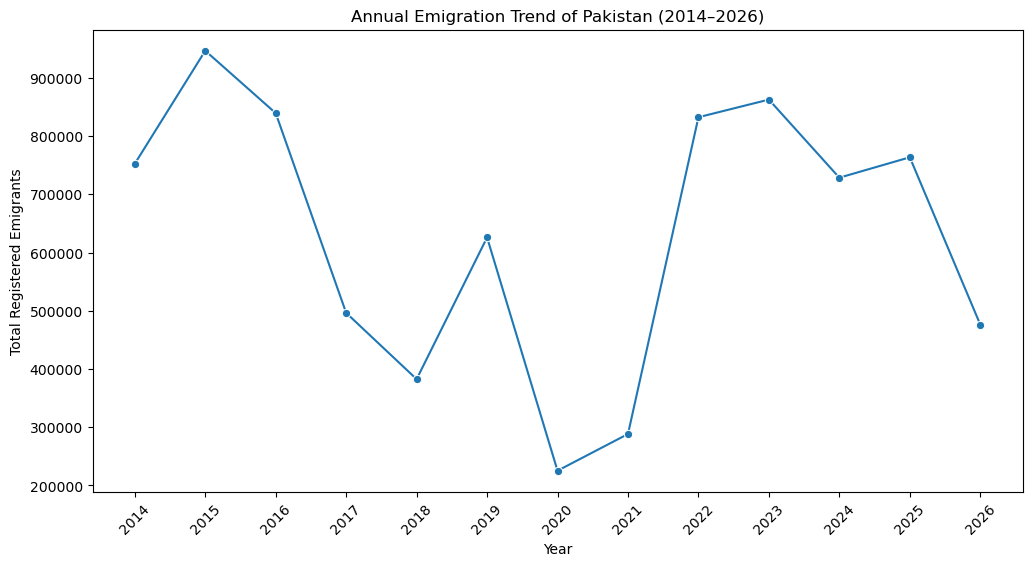

In [6]:
plt.figure(figsize = (12,6))

sns.lineplot(
    data=annual_emigration,
    x='Year',
    y='Total_Emigrants',
    marker='o',
)

plt.title('Annual Emigration Trend of Pakistan (2014–2026)')
plt.xlabel('Year')
plt.ylabel('Total Registered Emigrants')
plt.xticks(rotation=45)

plt.show()

### Identify the top 10 districts

In [7]:
top_10 = df.nlargest(10, "Total")[["Districts", "Total"]]
top_10

,Districts,Total
34,Sialkot,342969
9,Gujranwala,295271
17,Lahore,266406
88,Swat,263876
7,Dera Ghazi Khan,254796
8,Faisalabad,253119
80,Lower Dir,224320
30,Rawalpindi,222848
44,Karachi (Central),190590
83,Mardan,183453


### Visualization

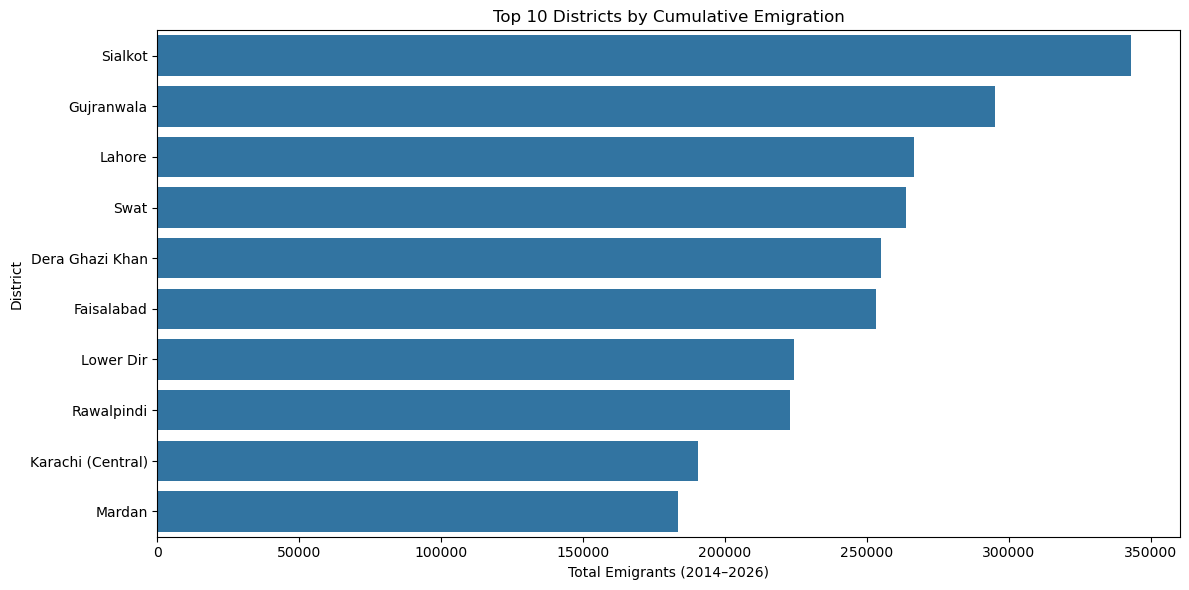

In [8]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_10,
    x='Total',
    y='Districts'
)

plt.title('Top 10 Districts by Cumulative Emigration')
plt.xlabel('Total Emigrants (2014–2026)')
plt.ylabel('District')

plt.tight_layout()
plt.show()

### Bottom 10 Districts

In [9]:
bottom_10 = df.nsmallest(10, 'Total')[['Districts', 'Total']]

display(bottom_10)

,Districts,Total
121,Lehri,37
153,Skardu,96
105,Bolan,129
109,Harnai,158
132,Sohbatpur,164
133,Turbat,195
118,Killa Saifullah,238
136,Ziarat,243
148,Diamir,286
112,Kachhi,315


### Visualization

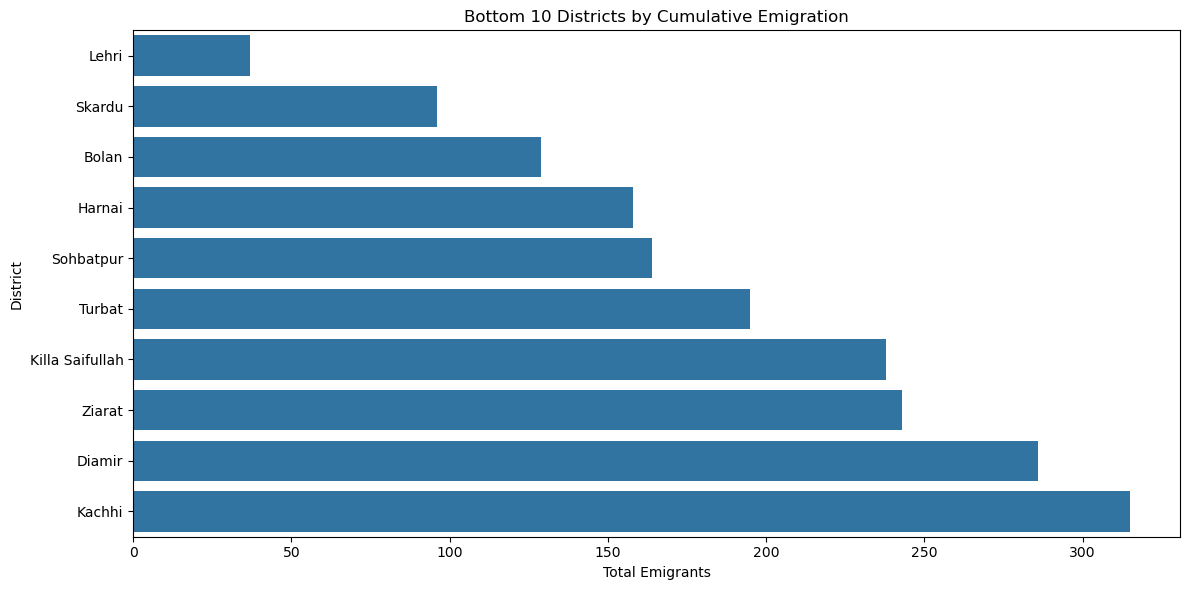

In [10]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=bottom_10,
    x='Total',
    y='Districts'
)

plt.title('Bottom 10 Districts by Cumulative Emigration')
plt.xlabel('Total Emigrants')
plt.ylabel('District')

plt.tight_layout()
plt.show()

### Year-over-year (YoY) growth analysis

In [11]:
annual_emigration['YoY_Growth_%'] = (
    annual_emigration['Total_Emigrants'].pct_change() * 100
).round(2)

display(annual_emigration)

,Year,Total_Emigrants,YoY_Growth_%
0,2014,752466,NaN
1,2015,946571,25.80
2,2016,839353,-11.33
3,2017,496286,-40.87
4,2018,382439,-22.94
5,2019,625876,63.65
6,2020,225213,-64.02
7,2021,288280,28.00
8,2022,832339,188.73
9,2023,862625,3.64


### Visualization

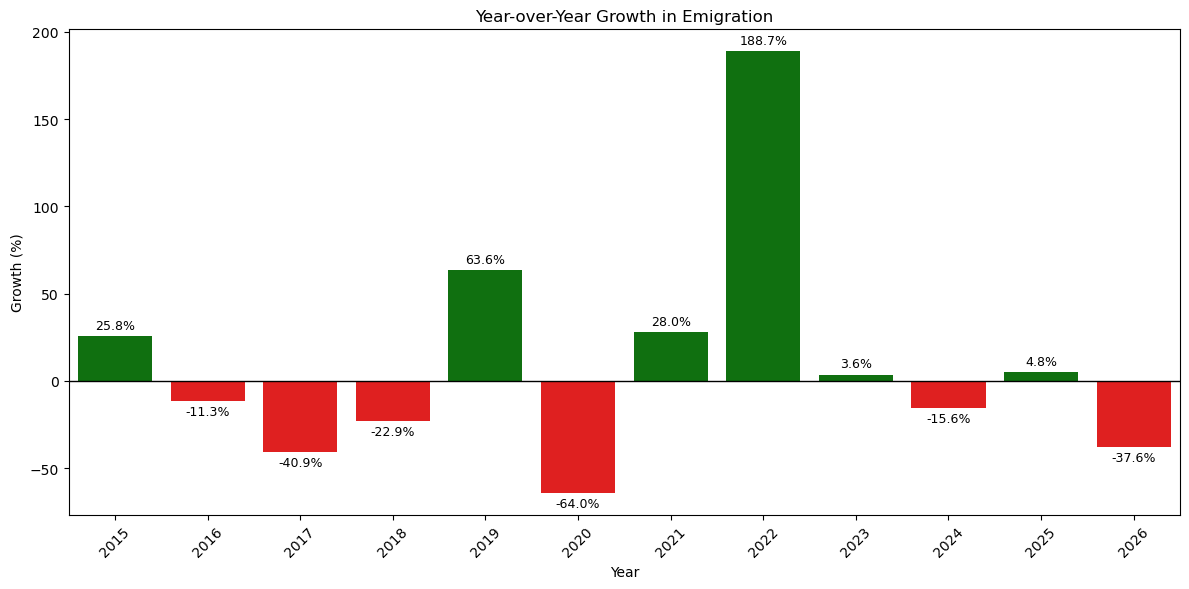

In [13]:
plt.figure(figsize=(12, 6))

vals = annual_emigration.iloc[1:]['YoY_Growth_%']
colors = ['red' if v < 0 else 'green' for v in vals]

ax = sns.barplot(
    data=annual_emigration.iloc[1:],
    x='Year',
    y='YoY_Growth_%',
    palette=colors,
    hue='Year',
    legend=False
)

# Add value labels on each bar
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3, fontsize=9)

plt.axhline(0, color='black', linewidth=1)
plt.title('Year-over-Year Growth in Emigration')
plt.xlabel('Year')
plt.ylabel('Growth (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Top 5 District-wise annual trend analysis 

In [18]:
top_5_districts = df.nlargest(5, 'Total')['Districts']

# Select their annual observations
top_5_data = df[
    df['Districts'].isin(top_5_districts)
].set_index('Districts')[years].T

display(top_5_data)

Districts,Dera Ghazi Khan,Gujranwala,Lahore,Sialkot,Swat
2014,19362,24826,26048,27943,16289
2015,31744,32655,30169,33891,28485
2016,24914,31464,26237,36016,25389
2017,9566,17857,17301,23036,11074
2018,8785,12577,11861,15776,9920
2019,21578,19974,15695,25068,25587
2020,8602,8005,6312,10579,9913
2021,13407,10449,8083,14743,11175
2022,36075,31846,22405,41672,32167
2023,34694,31374,33683,35866,24934


### Visualization

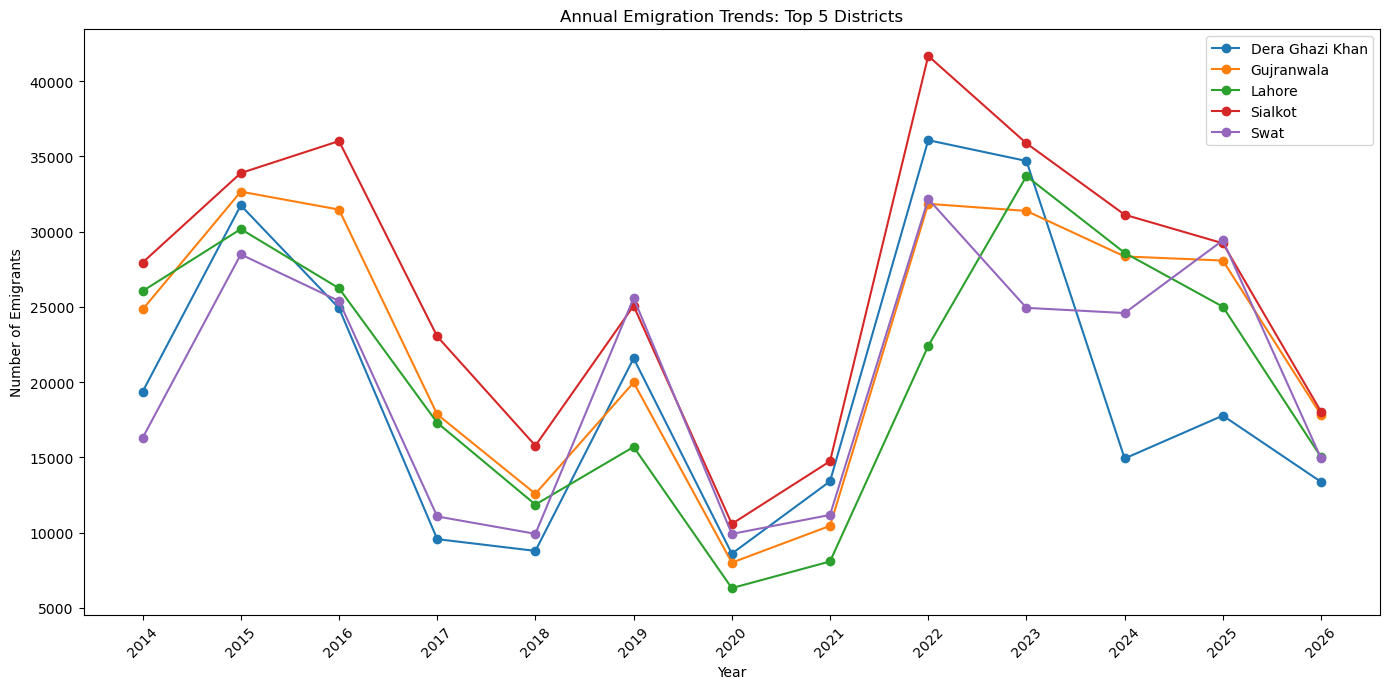

In [19]:
plt.figure(figsize=(14, 7))

for district in top_5_data.columns:
    plt.plot(
        top_5_data.index,
        top_5_data[district],
        marker='o',
        label=district
    )

plt.title('Annual Emigration Trends: Top 5 Districts')
plt.xlabel('Year')
plt.ylabel('Number of Emigrants')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### District contribution to national emigration

In [20]:
national_total = df['Total'].sum()

df['Emigration_Share_%'] = (
    df['Total'] / national_total * 100
).round(2)

district_share = df.nlargest(15, 'Emigration_Share_%')[
    ['Districts', 'Total', 'Emigration_Share_%']
]

display(district_share)

,Districts,Total,Emigration_Share_%
34,Sialkot,342969,4.17
9,Gujranwala,295271,3.59
17,Lahore,266406,3.24
88,Swat,263876,3.21
7,Dera Ghazi Khan,254796,3.10
8,Faisalabad,253119,3.08
80,Lower Dir,224320,2.73
30,Rawalpindi,222848,2.71
44,Karachi (Central),190590,2.32
83,Mardan,183453,2.23


### Visualization

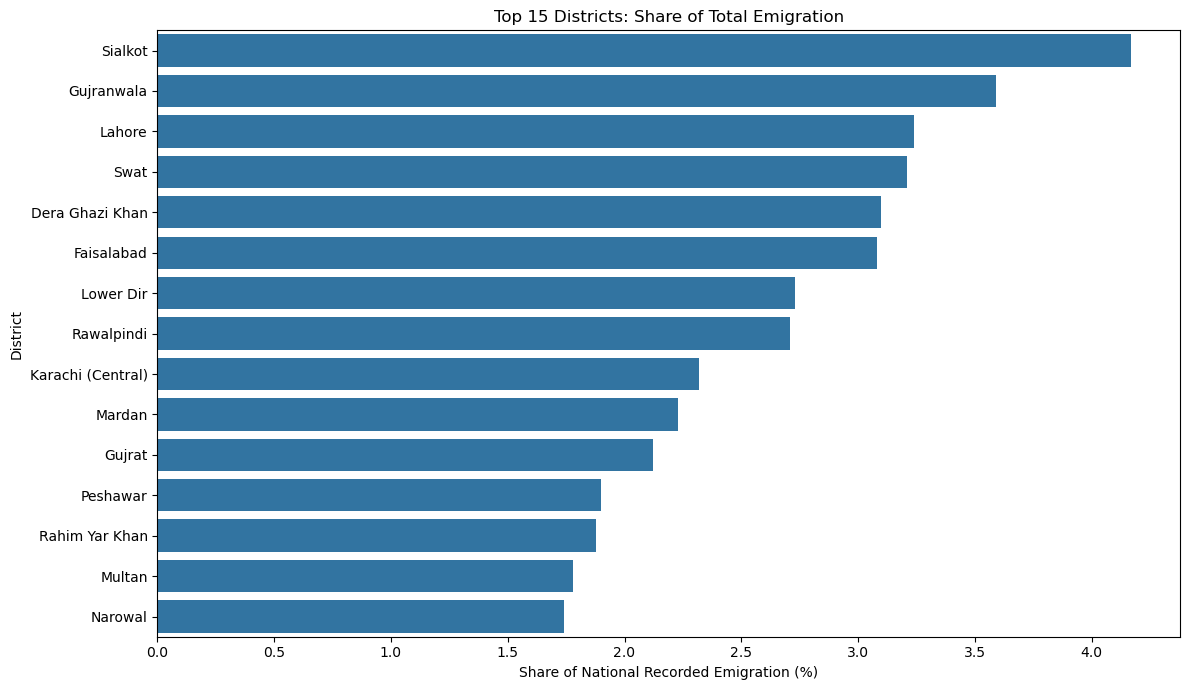

In [21]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=district_share,
    x='Emigration_Share_%',
    y='Districts'
)

plt.title('Top 15 Districts: Share of Total Emigration')
plt.xlabel('Share of National Recorded Emigration (%)')
plt.ylabel('District')

plt.tight_layout()
plt.show()

### Top 20 District-wise emigration heatmap

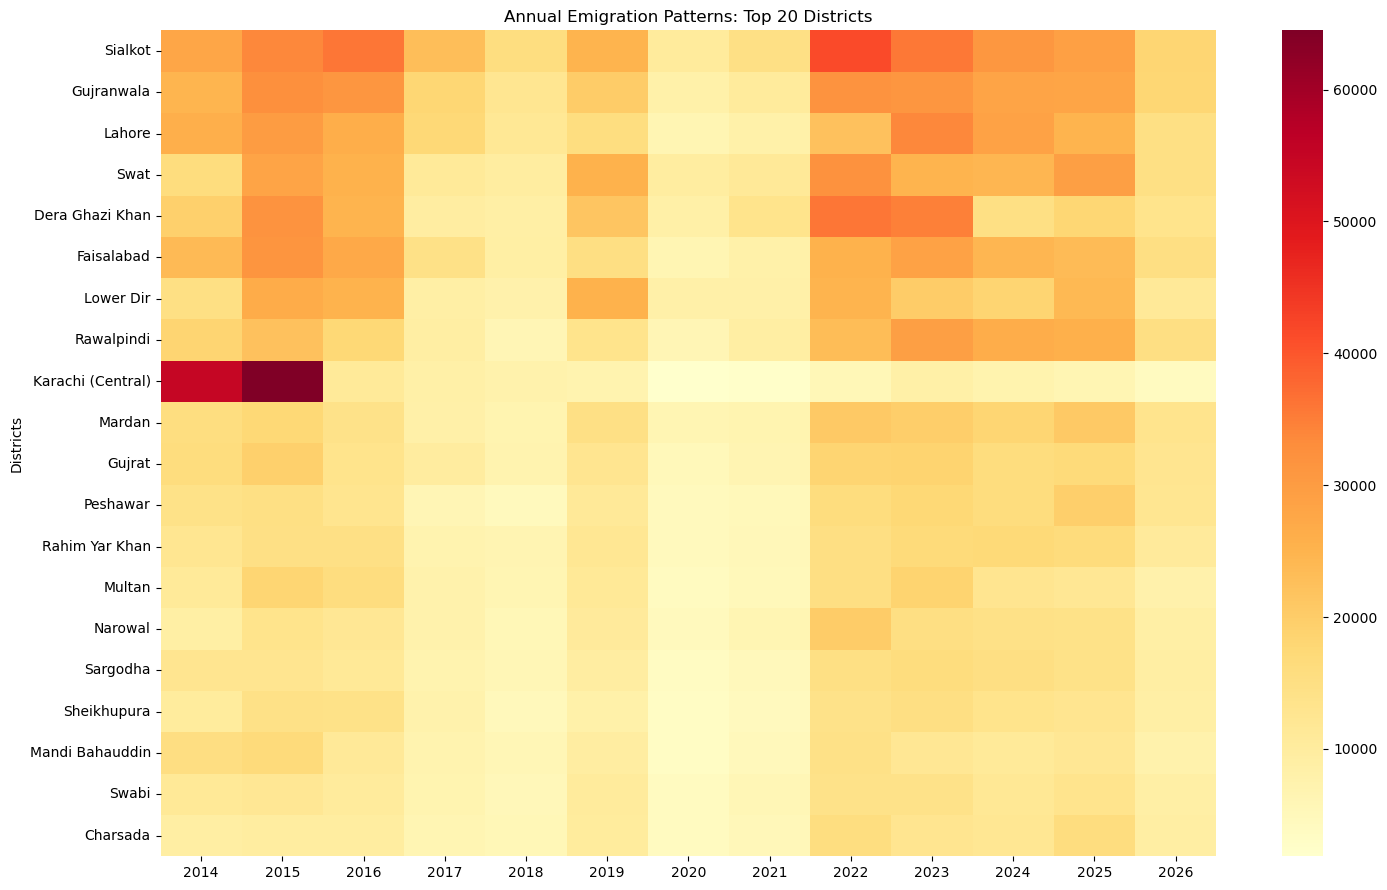

In [22]:
top_20 = df.nlargest(20, 'Total')

plt.figure(figsize=(15, 9))

sns.heatmap(
    top_20.set_index('Districts')[years],
    cmap='YlOrRd',
    annot=False
)

plt.title('Annual Emigration Patterns: Top 20 Districts')
plt.tight_layout()
plt.show()

### Distribution of emigration across districts

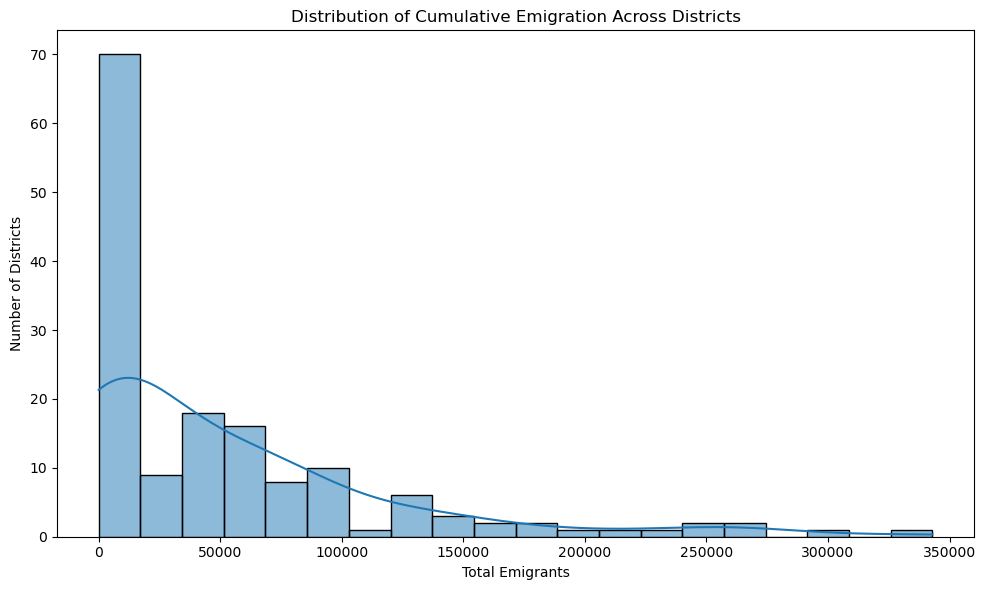

In [23]:
plt.figure(figsize=(10, 6))

sns.histplot(
    df['Total'],
    bins=20,
    kde=True
)

plt.title('Distribution of Cumulative Emigration Across Districts')
plt.xlabel('Total Emigrants')
plt.ylabel('Number of Districts')

plt.tight_layout()
plt.show()

In [37]:
print("Skewness:", df['Total'].skew())
print("Kurtosis:", df['Total'].kurt())

Skewness: 1.9078067587738756
Kurtosis: 3.853947127582808


In [24]:
Q1 = df['Total'].quantile(0.25)
Q3 = df['Total'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df['Total'] < lower_bound) |
    (df['Total'] > upper_bound)
]

display(outliers[['Districts', 'Total']])

,Districts,Total
7,Dera Ghazi Khan,254796
8,Faisalabad,253119
9,Gujranwala,295271
17,Lahore,266406
30,Rawalpindi,222848
34,Sialkot,342969
80,Lower Dir,224320
88,Swat,263876


### Identify outliers using the IQR method

In [25]:
Q1 = df['Total'].quantile(0.25)
Q3 = df['Total'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df['Total'] < lower_bound) |
    (df['Total'] > upper_bound)
]

display(outliers[['Districts', 'Total']])

,Districts,Total
7,Dera Ghazi Khan,254796
8,Faisalabad,253119
9,Gujranwala,295271
17,Lahore,266406
30,Rawalpindi,222848
34,Sialkot,342969
80,Lower Dir,224320
88,Swat,263876


### Visualization

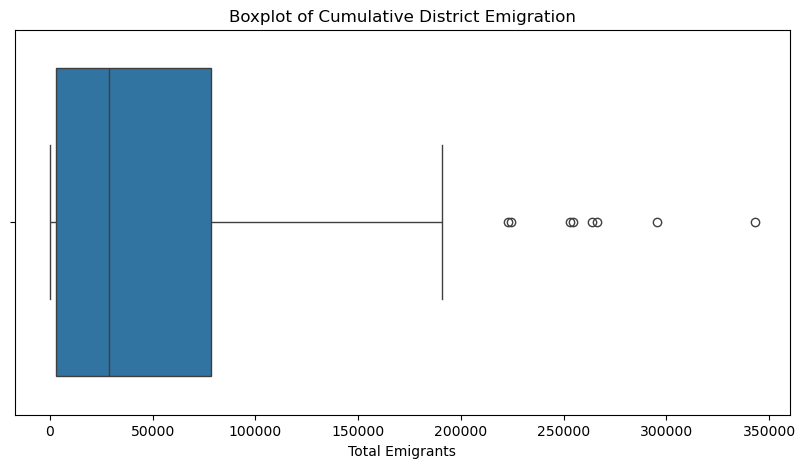

In [26]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df['Total'])

plt.title('Boxplot of Cumulative District Emigration')
plt.xlabel('Total Emigrants')

plt.show()

### Compare emigration before and during/after COVID-19

In [28]:
periods = {
    'Pre-COVID (2014–2019)': [str(y) for y in range(2014, 2020)],
    'COVID Period (2020–2021)': ['2020', '2021'],
    'Post-COVID (2022–2025)': [str(y) for y in range(2022, 2026)]
}

period_analysis = {}

for period, cols in periods.items():
    period_analysis[period] = df[cols].sum().sum()

period_df = pd.DataFrame(
    list(period_analysis.items()),
    columns=['Period', 'Total_Emigrants']
)

display(period_df)

,Period,Total_Emigrants
0,Pre-COVID (2014–2019),4042991
1,COVID Period (2020–2021),513493
2,Post-COVID (2022–2025),3186999


### Visualization

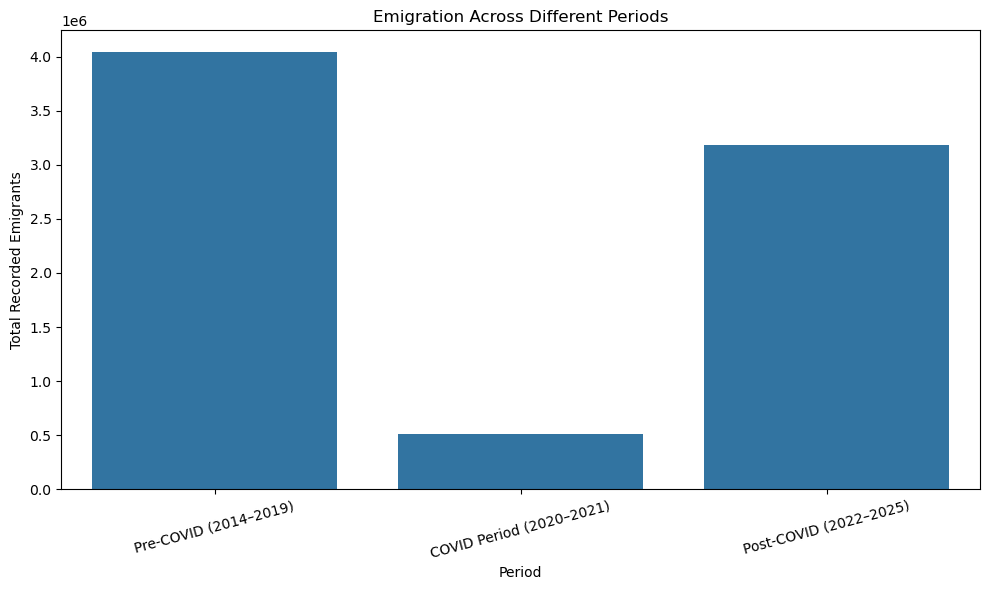

In [29]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=period_df,
    x='Period',
    y='Total_Emigrants'
)

plt.title('Emigration Across Different Periods')
plt.xlabel('Period')
plt.ylabel('Total Recorded Emigrants')

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [ ]:
### Key Findings

1. ## Key Findings – District-Wise Emigration from Pakistan (2014–2026)

Based on the exploratory data analysis, the following findings were identified:

### 1. District-wise Emigration
- Sialkot recorded the highest cumulative number of registered emigrants during the period under examination.
- Gujranwala, Lahore, Swat, and Dera Ghazi Khan were also among the districts with the highest recorded emigration.
- The distribution of emigration across districts suggests that overseas employment registrations are not evenly distributed geographically.

### 2. Annual Emigration Trends
- Annual emigration figures experienced considerable fluctuations throughout the observation period.
- The highest annual number of registered emigrants was recorded in 2015.
- A substantial decline was observed in 2020, followed by a recovery in subsequent years.

### 3. Year-over-Year Growth
- Annual growth analysis reveals significant variations in registered emigration.
- The largest annual decline occurred during the COVID-19 period.
- Subsequent years show a recovery in recorded overseas employment migration.

### 4. Geographical Concentration
- A relatively small number of districts account for a substantial share of cumulative registered emigration.
- This indicates geographical concentration in the distribution of registered overseas employment.

### 5. District-level Variations
- Districts exhibit different patterns of annual emigration.
- Some districts maintain relatively consistent registration levels, while others experience considerable fluctuations.
- These differences highlight the importance of examining district-level trends rather than relying exclusively on national totals.

### 6. Distribution and Outlier Analysis
- The distribution of cumulative emigration across districts should be assessed using skewness and boxplot analysis.
- Districts identified as statistical outliers represent unusually high or low recorded figures and require further investigation.

### 7. Overall Conclusion
The analysis highlights substantial geographical and temporal variations in registered overseas employment migration from Pakistan. District-level analysis provides a more detailed understanding of the distribution and changing patterns of emigration than national-level figures alone.

Further research incorporating district population, unemployment, poverty, and socioeconomic indicators could provide additional insights into the factors associated with overseas employment migration.

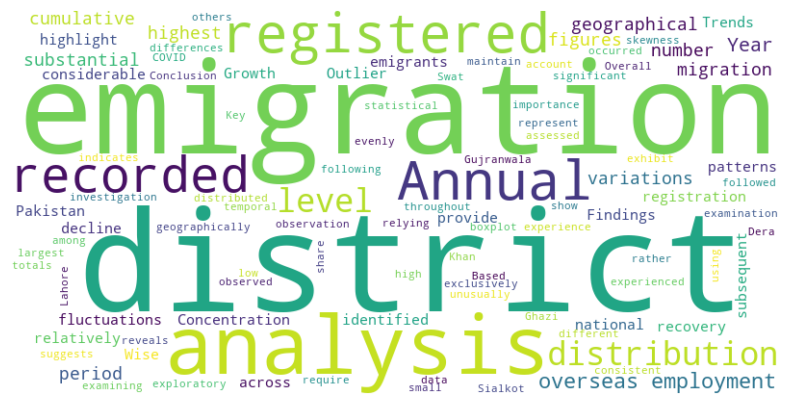

In [30]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

text = """1. ## Key Findings – District-Wise Emigration from Pakistan (2014–2026)

Based on the exploratory data analysis, the following findings were identified:

### 1. District-wise Emigration
- Sialkot recorded the highest cumulative number of registered emigrants during the period under examination.
- Gujranwala, Lahore, Swat, and Dera Ghazi Khan were also among the districts with the highest recorded emigration.
- The distribution of emigration across districts suggests that overseas employment registrations are not evenly distributed geographically.

### 2. Annual Emigration Trends
- Annual emigration figures experienced considerable fluctuations throughout the observation period.
- The highest annual number of registered emigrants was recorded in 2015.
- A substantial decline was observed in 2020, followed by a recovery in subsequent years.

### 3. Year-over-Year Growth
- Annual growth analysis reveals significant variations in registered emigration.
- The largest annual decline occurred during the COVID-19 period.
- Subsequent years show a recovery in recorded overseas employment migration.

### 4. Geographical Concentration
- A relatively small number of districts account for a substantial share of cumulative registered emigration.
- This indicates geographical concentration in the distribution of registered overseas employment.

### 5. District-level Variations
- Districts exhibit different patterns of annual emigration.
- Some districts maintain relatively consistent registration levels, while others experience considerable fluctuations.
- These differences highlight the importance of examining district-level trends rather than relying exclusively on national totals.

### 6. Distribution and Outlier Analysis
- The distribution of cumulative emigration across districts should be assessed using skewness and boxplot analysis.
- Districts identified as statistical outliers represent unusually high or low recorded figures and require further investigation.

### 7. Overall Conclusion
The analysis highlights substantial geographical and temporal variations in registered overseas employment migration from Pakistan. District-level analysis provides a more detailed understanding of the distribution and changing patterns of emigration than national-level figures alone.

Further research incorporating district population, unemployment, poverty, and socioeconomic indicators could provide additional insights into the factors associated with overseas employment migration.

"""

wc = WordCloud(
    width=800,
    height=400,
    background_color='white',
    max_words=100,
).generate(text)

plt.figure(figsize=(10, 5))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.show()